In [53]:
import random
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from collections import deque

In [54]:
#create the map
ship = np.array([
    [0, 0, 0, 0, 0],
    [0, 1, 1, 0, 0],
    [0, 0, 0, 0, 1],
    [0, 1, 0, 0, 0],
    [0, 0, 0, 0, 0]
])

print(ship)

[[0 0 0 0 0]
 [0 1 1 0 0]
 [0 0 0 0 1]
 [0 1 0 0 0]
 [0 0 0 0 0]]


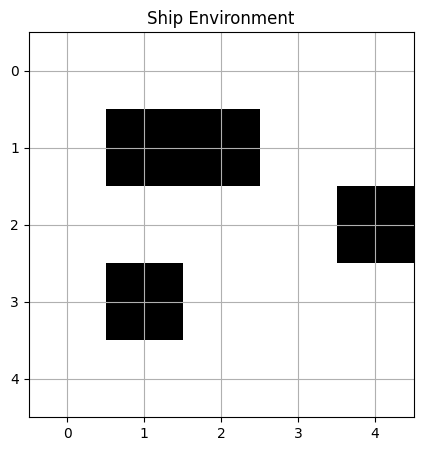

In [55]:
#draw the map
plt.figure(figsize=(5, 5))
plt.imshow(ship, cmap="Greys")

plt.xticks(range(5))
plt.yticks(range(5))
plt.grid()

plt.title("Ship Environment")
plt.show()

In [56]:
def bfs(ship, start, goal):
#define the function and the ship map, start and goal

    queue = deque([start])
    visited = {start}
    parent = {start: None}#record the previous step

    directions = [
        (-1, 0), (1, 0), (0, -1), (0, 1)]

#get the position
    while queue:

        current = queue.popleft()

        if current == goal:
            break

        row, col = current

        for dr, dc in directions:

            nr = row + dr
            nc = col + dc
            neighbor = (nr, nc)

            if (
                0 <= nr < ship.shape[0]
                and 0 <= nc < ship.shape[1]
                and ship[nr, nc] == 0
                and neighbor not in visited
            ):

                visited.add(neighbor)
                parent[neighbor] = current
                queue.append(neighbor)

    if goal not in visited:
        return None

    path = []
    current = goal

    while current is not None:
        path.append(current)
        current = parent[current]

    path.reverse()

    return path

In [57]:
#test the BFS
start = (0, 0)
goal = (4, 4)

path = bfs(ship, start, goal)

print("Shortest path:", path)

if path is not None:
    print("number of moves:", len(path) - 1)

Shortest path: [(0, 0), (1, 0), (2, 0), (3, 0), (4, 0), (4, 1), (4, 2), (4, 3), (4, 4)]
number of moves: 8


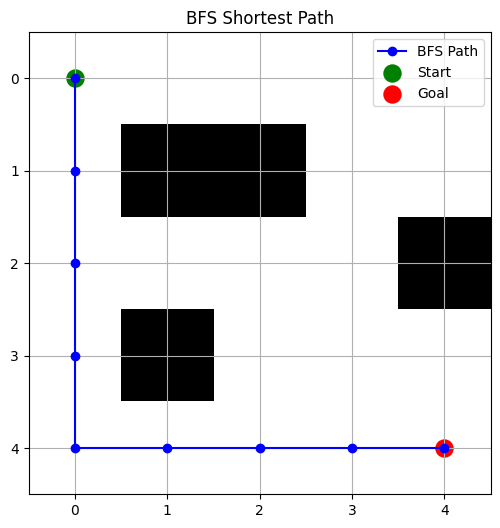

In [58]:
#plt
plt.figure(figsize=(6, 6))
plt.imshow(ship, cmap="Greys")

if path is not None:
    rows = [p[0] for p in path]
    cols = [p[1] for p in path]

    plt.plot(cols, rows, "b-o", label="BFS Path")

plt.scatter(start[1], start[0],
            color="green", s=150, label="Start")

plt.scatter(goal[1], goal[0],
            color="red", s=150, label="Goal")

plt.xticks(range(ship.shape[1]))
plt.yticks(range(ship.shape[0]))
plt.grid()

plt.title("BFS Shortest Path")
plt.legend()
plt.show()

In [59]:
#Type A detector
def detector_type_a(locator_pos, lost_pos, k):

    lr, lc = locator_pos
    br, bc = lost_pos
    #LocatorBot current position
    if locator_pos == lost_pos:
        return "FOUND"

    if abs(lr - br) <= k and abs(lc - bc) <= k:
        return "PING"

    return "NO PING"

locator_pos = (2, 2)
lost_pos = (3, 3)

print(detector_type_a(locator_pos, lost_pos, 1))
print(detector_type_a(locator_pos, lost_pos, 0))
print(detector_type_a(locator_pos, locator_pos, 1))

PING
NO PING
FOUND


In [60]:
possible_positions = set()

for r in range(ship.shape[0]):
    for c in range(ship.shape[1]):

        if ship[r, c] == 0:
            possible_positions.add((r, c))

print("Possible positions:", len(possible_positions))

Possible positions: 21


In [61]:
def update_knowledge_type_a(possible_positions, locator_pos, k, result):

    lr, lc = locator_pos

    detection_area = set()

    for r, c in possible_positions:
        if abs(r - lr) <= k and abs(c - lc) <= k:
            detection_area.add((r, c))

    if result == "PING":
        return possible_positions & detection_area

    elif result == "NO PING":
        return possible_positions - detection_area

    elif result == "FOUND":
        return {locator_pos}

    return possible_positions

In [62]:
#test knowledgebase update
locator_pos = (2, 2)
lost_pos = (3, 3)
k = 1

result = detector_type_a(locator_pos, lost_pos, k)

new_positions = update_knowledge_type_a(
    possible_positions,
    locator_pos,
    k,
    result
)

print("Detector result:", result)
print("Before update:", len(possible_positions))
print("After update:", len(new_positions))
print("Remaining positions:", sorted(new_positions))

Detector result: PING
Before update: 21
After update: 6
Remaining positions: [(1, 3), (2, 1), (2, 2), (2, 3), (3, 2), (3, 3)]


In [63]:
#realize baseline strategy
def find_nearest_position(ship, current_pos, possible_positions):

    nearest_positions = []
    shortest_distance = float("inf")

    for pos in sorted(possible_positions):

        if pos == current_pos:
            continue

        path = bfs(ship, current_pos, pos)

        if path is None:
            continue

        distance = len(path) - 1

        if distance < shortest_distance:
            shortest_distance = distance
            nearest_positions = [pos]

        elif distance == shortest_distance:
            nearest_positions.append(pos)

    if not nearest_positions:
        return None

    return random.choice(nearest_positions)

In [64]:
#test 
current_pos = (2, 2)

nearest = find_nearest_position(
    ship,
    current_pos,
    new_positions
)

print("Nearest possible position:", nearest)
print("Shortest path:", bfs(ship, current_pos, nearest))

Nearest possible position: (2, 1)
Shortest path: [(2, 2), (2, 1)]


In [65]:
#baselineA
def baseline_type_a(ship, start, lost_pos, k):

    current_pos = start
    full_path = [start]

    possible_positions = {
        (r, c)
        for r in range(ship.shape[0])
        for c in range(ship.shape[1])
        if ship[r, c] == 0
    }

    moves = 0
    detections = 0

    while True:

        #run detector
        result = detector_type_a(current_pos, lost_pos, k)
        detections += 1

        if result == "FOUND":
            break

        #update knowledge base
        possible_positions = update_knowledge_type_a(
            possible_positions,
            current_pos,
            k,
            result
        )

        #current cell is confirmed empty
        possible_positions.discard(current_pos)

        #find nearest possible location
        target = find_nearest_position(
            ship,
            current_pos,
            possible_positions
        )

        if target is None:
            raise RuntimeError("No reachable candidate remains.")

        #move to target using BFS
        path = bfs(ship, current_pos, target)

        moves += len(path) - 1
        full_path.extend(path[1:])
        current_pos = target

    total_cost = moves + 0.5 * detections

    return {
        "moves": moves,
        "detections": detections,
        "total_cost": total_cost,
        "path": full_path
    }

In [66]:
#test
random.seed(42)

start = (0, 0)
lost_pos = (4, 4)
k = 1

result = baseline_type_a(ship, start, lost_pos, k)

print(result)

{'moves': 16, 'detections': 8, 'total_cost': 20.0, 'path': [(0, 0), (0, 1), (0, 2), (0, 3), (0, 4), (1, 4), (1, 3), (2, 3), (2, 2), (2, 1), (2, 0), (3, 0), (4, 0), (4, 1), (4, 2), (4, 3), (4, 4)]}


In [67]:
random.seed(42)

result = baseline_type_a(
    ship,
    (0, 0),
    (4, 4),
    1
)

print("Moves:", result["moves"])
print("Detections:", result["detections"])
print("Total Cost:", result["total_cost"])
print("Path:", result["path"])

assert len(result["path"]) - 1 == result["moves"]

Moves: 16
Detections: 8
Total Cost: 20.0
Path: [(0, 0), (0, 1), (0, 2), (0, 3), (0, 4), (1, 4), (1, 3), (2, 3), (2, 2), (2, 1), (2, 0), (3, 0), (4, 0), (4, 1), (4, 2), (4, 3), (4, 4)]


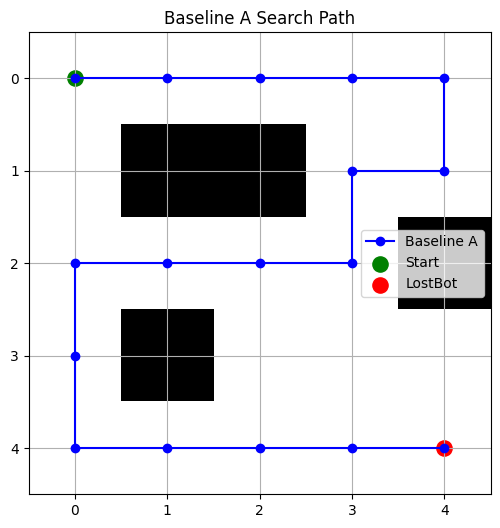

In [68]:
path = result["path"]

rows = [p[0] for p in path]
cols = [p[1] for p in path]

plt.figure(figsize=(6, 6))
plt.imshow(ship, cmap="Greys")

plt.plot(cols, rows, "b-o", label="Baseline A")

plt.scatter(0, 0, color="green", s=120, label="Start")
plt.scatter(4, 4, color="red", s=120, label="LostBot")

plt.xticks(range(ship.shape[1]))
plt.yticks(range(ship.shape[0]))
plt.grid()
plt.legend()
plt.title("Baseline A Search Path")

plt.show()

In [69]:
def information_gain_type_a(possible_positions, pos, k):

    if not possible_positions:
        return 0

    r, c = pos

    inside = 0

    for pr, pc in possible_positions:
        if abs(pr - r) <= k and abs(pc - c) <= k:
            inside += 1

    p = inside / len(possible_positions)

    if p == 0 or p == 1:
        return 0

    ig = -p * math.log2(p) - (1 - p) * math.log2(1 - p)

    return ig

In [70]:
test_positions = {
    (0, 0), (0, 1), (0, 2),
    (1, 0), (1, 1), (1, 2)
}

print(information_gain_type_a(test_positions, (0, 0), 1))
print(information_gain_type_a(test_positions, (0, 1), 1))

0.9182958340544896
0


In [71]:
#select the detect target
def choose_detection_target(ship, current_pos, possible_positions, k, beta=0.95):

    candidates = []

    for r in range(ship.shape[0]):
        for c in range(ship.shape[1]):

            if ship[r, c] == 1:
                continue

            pos = (r, c)
            path = bfs(ship, current_pos, pos)

            if path is None:
                continue

            ig = information_gain_type_a(possible_positions, pos, k)
            distance = len(path) - 1

            candidates.append((pos, ig, distance))

    if not candidates:
        return None

    max_ig = max(item[1] for item in candidates)

    if max_ig == 0:
        return find_nearest_position(
            ship, current_pos, possible_positions
        )

    good_positions = [
        item for item in candidates
        if item[1] >= beta * max_ig
    ]

    best = min(good_positions, key=lambda x: (x[2], -x[1]))

    return best[0]

In [72]:
current_pos = (0, 0)
k = 1

target = choose_detection_target(
    ship,
    current_pos,
    possible_positions,
    k
)

print("Selected detection target:", target)

print("Information Gain:",
      information_gain_type_a(possible_positions, target, k))

print("Shortest Path:", bfs(ship, current_pos, target))

Selected detection target: (1, 3)
Information Gain: 0.9182958340544896
Shortest Path: [(0, 0), (0, 1), (0, 2), (0, 3), (1, 3)]


In [73]:
#realize Improved TypeA
def improved_type_a(ship, start, lost_pos, k, beta=0.95):

    current_pos = start

    possible_positions = {
        (r, c)
        for r in range(ship.shape[0])
        for c in range(ship.shape[1])
        if ship[r, c] == 0
    }

    moves = 0
    detections = 0
    full_path = [start]

    while True:

        #first check the current position
        result = detector_type_a(current_pos, lost_pos, k)
        detections += 1

        if result == "FOUND":
            break

        possible_positions = update_knowledge_type_a(
            possible_positions, current_pos, k, result
        )

        possible_positions.discard(current_pos)

        #choose a useful detection location
        target = choose_detection_target(
            ship, current_pos, possible_positions, k, beta
        )

        if target is None:
            raise RuntimeError("No reachable candidate remains.")

        #if already at target, choose nearest possible location
        if target == current_pos:
            target = find_nearest_position(
                ship, current_pos, possible_positions
            )

        path = bfs(ship, current_pos, target)

        moves += len(path) - 1
        full_path.extend(path[1:])
        current_pos = target

    total_cost = moves + 0.5 * detections

    return {
        "moves": moves,
        "detections": detections,
        "total_cost": total_cost,
        "path": full_path
    }

In [74]:
random.seed(42)
#test improvedA
improved_result = improved_type_a(
    ship,
    (0, 0),
    (4, 4),
    1
)

print(improved_result)

print("Baseline:", result["total_cost"])
print("Improved:", improved_result["total_cost"])

{'moves': 12, 'detections': 6, 'total_cost': 15.0, 'path': [(0, 0), (0, 1), (0, 2), (0, 3), (1, 3), (2, 3), (3, 3), (2, 3), (3, 3), (3, 2), (4, 2), (4, 3), (4, 4)]}
Baseline: 20.0
Improved: 15.0


In [75]:
k_values = [0, 1, 2, 3, 4] # r of different tests
num_trials = 100 #repeat each k 100times
#get the avaliable cells
open_cells = [
    (r, c)
    for r in range(ship.shape[0])
    for c in range(ship.shape[1])
    if ship[r, c] == 0
]
#choose 2 diff position randomly
random.seed(440)

start, lost_pos = random.sample(open_cells, 2)

print("LocatorBot:", start)
print("LostBot:", lost_pos)

LocatorBot: (0, 3)
LostBot: (0, 2)


In [76]:
random.seed(440)

results = []

for k in k_values:

    for trial in range(num_trials):

        #random starting and target positions
        start, lost_pos = random.sample(open_cells, 2)

        #baseline A
        baseline = baseline_type_a(
            ship, start, lost_pos, k
        )

        #improved A
        improved = improved_type_a(
            ship, start, lost_pos, k
        )

        results.append({
            "k": k,
            "trial": trial,
            "baseline_cost": baseline["total_cost"],
            "improved_cost": improved["total_cost"],
            "baseline_moves": baseline["moves"],
            "improved_moves": improved["moves"],
            "baseline_detections": baseline["detections"],
            "improved_detections": improved["detections"]
        })

print("Experiments completed:", len(results))

Experiments completed: 500


In [77]:
df = pd.DataFrame(results)

summary = df.groupby("k")[
    ["baseline_cost", "improved_cost"]
].mean()

summary["improvement_%"] = (
    (summary["baseline_cost"] - summary["improved_cost"])
    / summary["baseline_cost"] * 100
)

display(summary.round(2))

,baseline_cost,improved_cost,improvement_%
k,,,
0,18.03,16.29,9.65
1,8.88,11.20,-26.11
2,8.94,15.20,-70.06
3,11.21,17.12,-52.72
4,17.80,18.55,-4.19


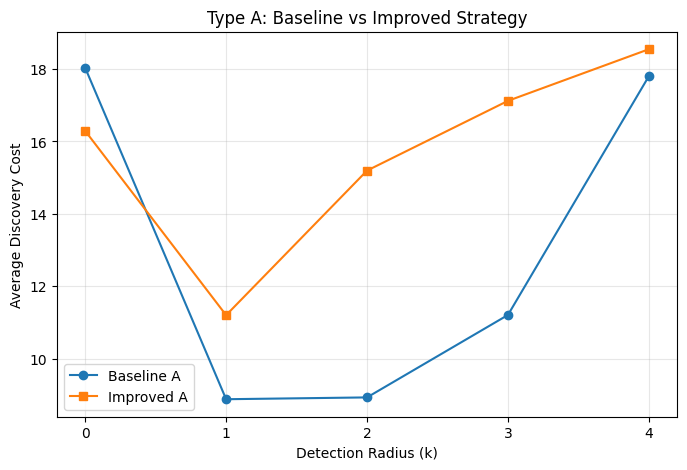

In [78]:
plt.figure(figsize=(8, 5))

plt.plot(
    summary.index,
    summary["baseline_cost"],
    marker="o",
    label="Baseline A"
)

plt.plot(
    summary.index,
    summary["improved_cost"],
    marker="s",
    label="Improved A"
)

plt.xlabel("Detection Radius (k)")
plt.ylabel("Average Discovery Cost")
plt.title("Type A: Baseline vs Improved Strategy")

plt.xticks(k_values)
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [79]:
#improvement
def choose_detection_target_v2(ship, current_pos, possible_positions, k):

    best_target = None
    best_score = -1

    for r in range(ship.shape[0]):
        for c in range(ship.shape[1]):

            if ship[r, c] == 1:
                continue

            pos = (r, c)

            path = bfs(ship, current_pos, pos)

            if path is None:
                continue

            distance = len(path) - 1

            ig = information_gain_type_a(
                possible_positions, pos, k
            )

            score = ig / (distance + 1)

            if score > best_score:
                best_score = score
                best_target = pos

    return best_target

In [80]:
current_pos = (0, 0)
k = 2

target = choose_detection_target_v2(
    ship,
    current_pos,
    possible_positions,
    k
)

print("New target:", target)
print("Distance:", len(bfs(ship, current_pos, target)) - 1)
print("Information Gain:",
      information_gain_type_a(possible_positions, target, k))

New target: (0, 0)
Distance: 0
Information Gain: 0.9182958340544896


In [81]:
def should_detect_type_a(possible_positions, current_pos, k):

    ig = information_gain_type_a(
        possible_positions,
        current_pos,
        k
    )

    return ig > 0

In [82]:
#test adaptive detection
current_pos = (0, 0)
k = 2

print("Before detection:",
      should_detect_type_a(possible_positions, current_pos, k))

result = detector_type_a(current_pos, (4, 4), k)

updated_positions = update_knowledge_type_a(
    possible_positions,
    current_pos,
    k,
    result
)

print("Detector result:", result)

print("After detection:",
      should_detect_type_a(updated_positions, current_pos, k))

Before detection: True
Detector result: NO PING
After detection: False
